# Experiment 3
## Optimal signature truncation order.
### Synthetic data

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.imports import *
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_synthetic
from src.utils import setup_latex_plotting

All imports are fine


### Load data

In [2]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])

### Fit RidgeSig models with different truncation orders to synthetic data

The code allows for different smoothing parameters that simulate different synthetic data sets. On each, ridge regression models on sliding-window signatures with varying truncation orders and window sizes are fitted.


In [3]:
smooth_params = [0.005]
sd = 500

delay_days = 2  
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
lambdas = np.logspace(-3, 3, 50)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
trunc_orders = [2,3,4,5,6,7]
lambdas = np.logspace(-1, 3, 20)
metric="rmse"

consumption_sim = np.empty((len(smooth_params), len(consumption)))
error_trunc_w   = np.empty((len(smooth_params), len(trunc_orders), len(windows)))

for i, alpha in enumerate(smooth_params):
    consumption_sim[i, :] = consumption_simulate(
        df, sd, smooth_param=alpha, fixed_seed=141
    )

    for j, d in enumerate(trunc_orders):
        for k, w in enumerate(windows):
            result = ridge_signatures(
                covariates=temp,
                target=consumption_sim[i, :],
                window=w,
                delay=48*delay_days,
                n_train=n_train,
                n_valid=n_valid,
                trunc_order=d,
                penalties=lambdas,
                tune_penalty=True,
                metric=metric
            )
            error_trunc_w[i, j, k] = result["error_test"]


Signature shape: (70128, 4)
X_train: (33552, 4)
X_val: (17520, 4)
X_test: (17520, 4)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 4)
X_train: (33552, 4)
X_val: (17520, 4)
X_test: (17520, 4)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 4)
X_train: (33552, 4)
X_val: (17520, 4)
X_test: (17520, 4)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 4)
X_train: (33552, 4)
X_val: (17520, 4)
X_test: (17520, 4)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 4)
X_train: (33552, 4)
X_val: (17520, 4)
X_test: (17520, 4)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 4)
X_train: (33552, 4)
X_val: (17520, 4)
X_test: (17520, 4)
-----------------------------------------
total tr

c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=2.91737e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
--------------------------

c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=9.12785e-20): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=1.48085e-19): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=2.40257e-19): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=3.89687e-19): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6

Signature shape: (70128, 120)
X_train: (33552, 120)
X_val: (17520, 120)
X_test: (17520, 120)
-----------------------------------------
total train+val+test: 68592
total data: 68592


...

Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592


c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=3.3374e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592


c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=1.02766e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 247)
X_train: (33552, 247)
X_val: (17520, 247)
X_test: (17520, 247)
--

### Plot
For the chosen smoothing parameter, the plot of error metric against different window sizes is obtained, with different colored curves corresponding to different depths.

findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

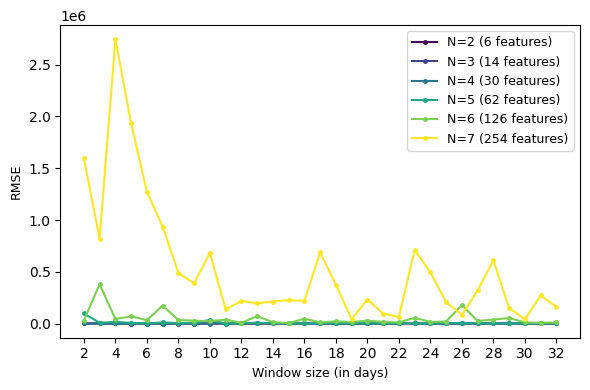

In [4]:
setup_latex_plotting()

n_trunc = len(trunc_orders)
cmap = mpl.colormaps["viridis"].resampled(n_trunc)  
colors = [cmap(i) for i in range(n_trunc)]

x = np.arange(n_windows)

tick_step = 2
xticks = np.arange(delay_days, n_windows + delay_days, tick_step)
xticklabels = xticks

fig, ax = plt.subplots(figsize=(6, 4))

for j, d in enumerate(trunc_orders):
    n_features = iisignature.siglength(2, d)
    
    ax.plot(
        x + delay_days,
        error_trunc_w[0, j],
        marker='.',
        markersize=5,
        color=colors[j],
        label=f"N={d} ({n_features} features)"
    )

ax.set_xlabel("Window size (in days)",fontsize=9)
ax.set_ylabel(metric.upper(),fontsize=9)
ax.set_xticks(xticks)
ax.set_xticklabels(xticklabels)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()